# Building an arbitrary distribution - sandbox

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for all plots in notebook
file = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_07/1rod_12oclock_1e7_85bins_2.5cmHL.csv"
z_slice = 25
norm_point = (0.0, 0.3)
bins = 85
dose_grid_half = 2.5
lattice = dose_grid_half*2/bins
source_transZ = -0.5
source_plane = cm_to_voxel(np.array(source_transZ), bins, dose_grid_half*2/bins)
applicator_rad = 0.3
source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-2.5, 2.5)
rngY = (-2.5, 2.5)

In [4]:
norm_energy, __ = extract_norm_energy(file, source_plane, 2, norm_point, bins, lattice)

In [5]:
X, Y, energy, __ = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy, zero_source=True, std_dev=False)

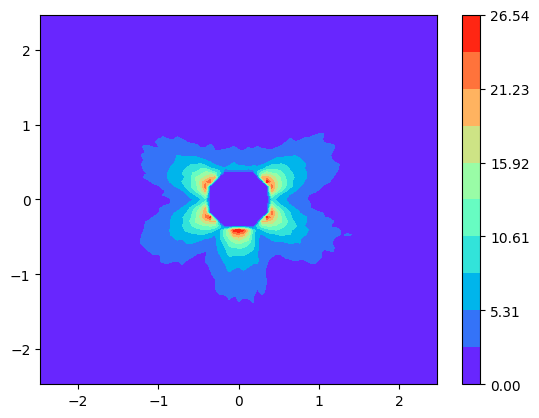

In [6]:
fig0, ax0 = plt.subplots()
contour0 = ax0.contourf(X, Y, energy, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar0 = fig0.colorbar(contour0)

## Rotation = 0 degrees

In [7]:
theta0 = 0
#rotation_60 = rotate_array(X, Y, energy, theta, bins, rngX, lattice)
rotation_0 = rotate_array_updated(X, Y, energy, theta0, bins, lattice)

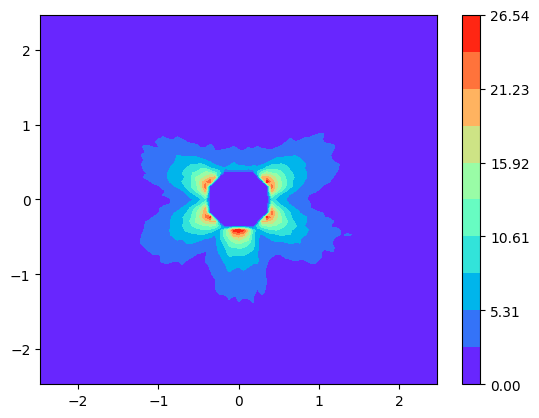

In [8]:
fig1, ax1 = plt.subplots()
contour1 = ax1.contourf(X, Y, rotation_0, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar1 = fig1.colorbar(contour1)

## Rotation = 60 degrees

In [9]:
theta60 = pi/3
rotation_60 = rotate_array_updated(X, Y, energy, theta60, bins, lattice)

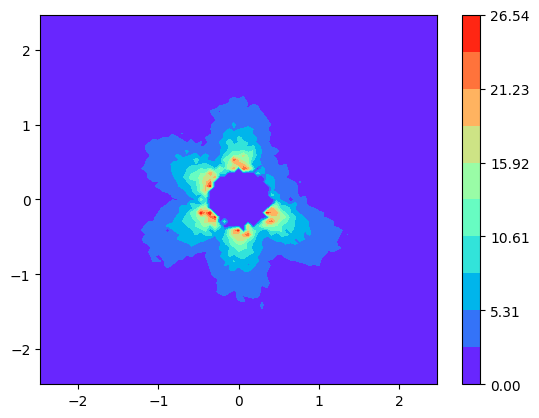

In [10]:
fig2, ax2 = plt.subplots()
contour2 = ax2.contourf(X, Y, rotation_60, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar2 = fig2.colorbar(contour2)

## Combining distributions

In [11]:
# Assuming numpy has a built-in function for this - on flight w/out wifi, so implementing naive algorithm myself
def element_min(array1, array2):
    # Assumes np.shape(array1) == np.shape(array2)
    output = np.zeros(np.shape(array1))
    
    for i in np.arange(0, np.shape(array1)[0]):
        for j in np.arange(0, np.shape(array1)[1]):
            min_value = min(array1[i][j], array2[i][j])
            output[i][j] = min_value

    return output

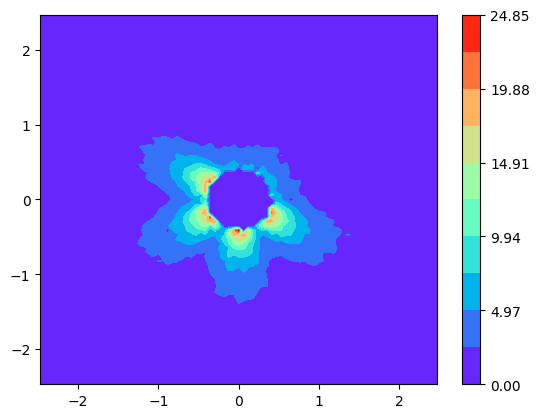

In [12]:
#test = element_min(rotation_0, rotation_60)
test = np.minimum(rotation_0, rotation_60)

fig3, ax3 = plt.subplots()
contour3 = ax3.contourf(X, Y, test, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar3 = fig3.colorbar(contour3)

In [13]:
# Let's compare the predicted distribution to the actual Monte Carlo output of 2 rods at 12 and 1 o'clock
file2 = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_08/2rod_12oclock_1e7_85bins_2.5cmHL.csv"

In [14]:
norm_energy2, __ = extract_norm_energy(file2, source_plane, 2, norm_point, bins, lattice)

In [15]:
X2, Y2, energy2, __ = contour_energy(file2, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy2, zero_source=True, std_dev=False)

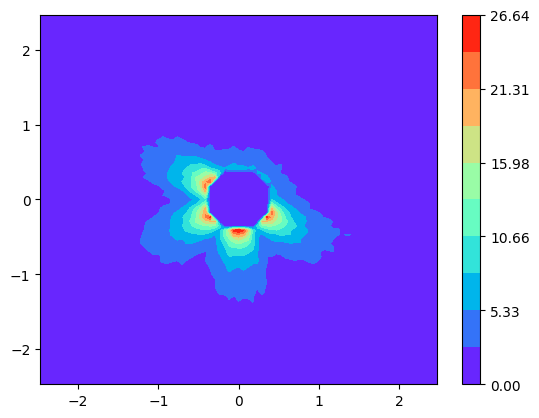

In [16]:
fig3, ax3 = plt.subplots()
contour3 = ax3.contourf(X2, Y2, energy2, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar3 = fig3.colorbar(contour3)

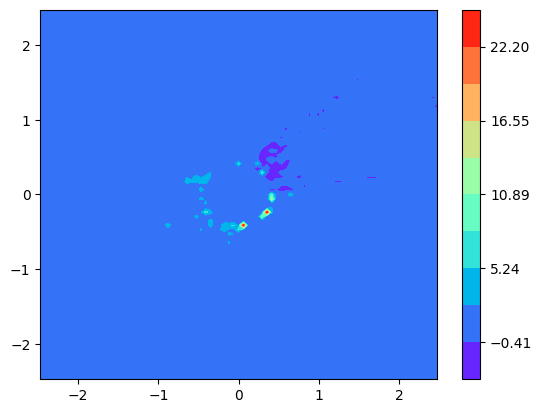

In [17]:
# To compare, we subtract the distributions - if they are identical, should end up with a totally zeroed contour plot
zeroed_plot = energy2 - test

fig4, ax4 = plt.subplots()
contour4 = ax4.contourf(X, Y, zeroed_plot, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar4 = fig4.colorbar(contour4)

# To do: I should look at quantifying the difference between actual and predicted distribution - use to optimize predictions?

Things to figure out:

    - Why does updated rotation code translate the distribution when range is reduced?
    - Why does original rotation code throw and out-of-bounds error when range is reduced?

## Combining distributions - 60 degrees and 240 degrees

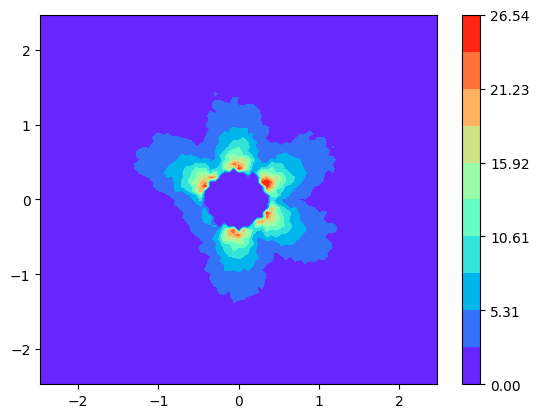

In [18]:
theta240 = 4*pi/3
rotation_240 = rotate_array_updated(X, Y, energy, theta240, bins, lattice)

fig5, ax5 = plt.subplots()
contour5 = ax5.contourf(X, Y, rotation_240, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar5 = fig5.colorbar(contour5)

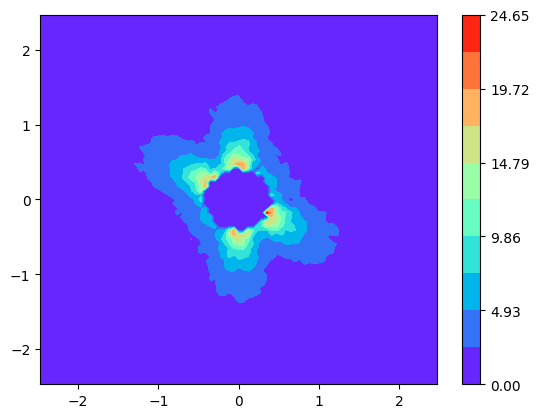

In [19]:
# Combining 60 degrees and 240 degrees
combo_60_240 = np.minimum(rotation_240, rotation_60)

fig6, ax6 = plt.subplots()
contour6 = ax6.contourf(X, Y, combo_60_240, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar6 = fig6.colorbar(contour6)

## Quantitative comparison of predicted vs actual distributions

Potential objective function for quantitative comparison:

$$ f(E, E') = \sum_{i} \sum_{j} | E_{ij} - E'_{ij} |^2 $$

In [20]:
# Testing objective function for rods inserted at 12 o'clock, 1 o'clock
def comparison_func(E1, E2):
    sum = 0
    for i in range(np.shape(E1)[0]):
        for j in range(np.shape(E1)[1]):
            diff = np.absolute(E1[i][j] - E2[i][j])**2
            sum += diff

    return sum

In [21]:
diff_12_1 = comparison_func(energy2/100, test/100)
print(diff_12_1)

0.2648964397176962


In [43]:
# Quantitative comparison for positions 1, 4 open
# Note that 180 degree rotations give better predictions than 60, 120, etc. rotations - will this affect comparison?
# Prediction for position 1 and 4 open
theta180 = pi
rotation_180 = rotate_array_updated(X, Y, energy, theta180, bins, lattice)

combo_0_180 = np.minimum(rotation_0, rotation_180)

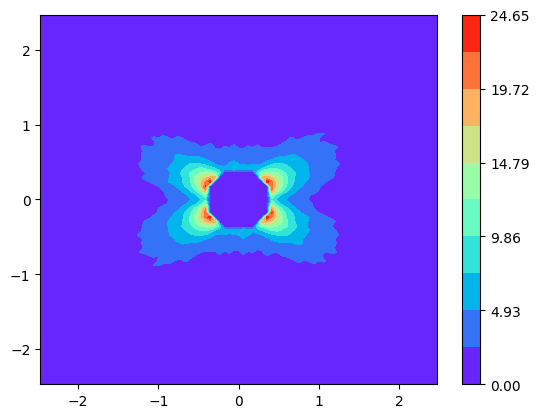

In [47]:
fig7, ax7 = plt.subplots()
contour7 = ax7.contourf(X, Y, combo_0_180, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar7 = fig7.colorbar(contour7)

In [45]:
# Importing data from simulation for positions 1,4 open
file14 = "/Users/seanmullane/Desktop/Research_2023/August_outputs/Results_08_08/2rod_14oclock_1e7_85bins_2.5cmHL.csv"

norm_energy14, __ = extract_norm_energy(file14, source_plane, 2, norm_point, bins, lattice)
X, Y, energy14, __ = contour_energy(file14, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad[4], 
                                               scale=True, norm_energy=norm_energy14, zero_source=True, std_dev=False)

In [46]:
# Comparison
diff_14 = comparison_func(combo_0_180/100, energy14/100)
print(diff_14)

0.01969562258341856
